# 第180章: GAN の基礎 — 2プレイヤーゲーム

## Generative Adversarial Networks as a Minimax Game

---

### このノートブックの位置づけ

196（6系統の総括）で、GAN は**他の5系統と決定的に違う**系統として測られました。

| 項目 | 196 での GAN の実測 |
|---|---|
| 対数尤度 | **計算できない**（他の5系統はすべて厳密か下界が出た） |
| サンプル品質（エネルギー距離） | 0.00791（中位） |
| 生成速度 | **2ms / 1万サンプル（最速）** |
| シード依存 | 8峰リングでエネルギー距離が 0.046〜0.216（**4.7倍**のばらつき） |

本章はこの「尤度が無い」「速い」「不安定」の3つが**同じ1つの設計判断から出ている**ことを示します。
その判断とは、**分布を直接書かず、2人のプレイヤーのゲームとして定義する**ことです。

$$\min_G \max_D \; V(D, G) =
\mathbb{E}_{x \sim p_{\text{data}}}\big[\log D(x)\big]
+ \mathbb{E}_{z \sim p_z}\big[\log\big(1 - D(G(z))\big)\big]$$

195 で「下に有界な損失は崩壊しない」ことを測りました。
**GAN にはそもそも『最小化すべき単一の目的関数』が存在しません。**
$G$ と $D$ が逆方向に動かす同じ量があるだけです。
この構造の違いが、本章で測る不安定性の根にあります。

### 学習目標

- [ ] 最小最大問題としての定式化を書き、最適判別器 $D^*(x) = p/(p+q)$ を導出できる
- [ ] $V(D^*) = 2\,\mathrm{JS}(p\|q) - 2\log 2$ を**数値積分で確認**できる
- [ ] 判別器を実際に学習させ、解析的な $D^*$ に近づくことを測定できる
- [ ] 飽和損失の勾配消失を、**分布の離れ具合に対して定量化**できる
- [ ] 非飽和損失が勾配消失を「遅らせる」が「消す」のではないことを示せる
- [ ] 交互最適化の振動を数値化し、尤度ベースの学習と比較できる
- [ ] 振動が GAN 固有でなく**最小最大問題そのものの性質**であることを、双線形ゲームで示せる

### 前提知識

| ノートブック | トピック |
|---|---|
| **196** | **6系統の総括（本章が GAN の位置を引き継ぐ）** |
| 195 | 下に有界な損失と安定性の関係 |
| 34 | KL ダイバージェンス（JS の定義に使う） |
| 31 | 最尤推定（比較対象） |
| 110-116 | 最適化（勾配ノルムの道具） |
| 305/306 | 既存の MLP vanilla GAN（本章はその理論的裏付け） |

**難易度**: ★★★★☆ | **所要時間**: 120-150分

> ⏱ **実行時間**: CPU で約3分半です。

## 目次

1. [環境セットアップ](#setup)
2. [最適判別器と JS ダイバージェンス](#optimal-d)
3. [飽和損失の勾配消失](#vanishing)
4. [交互最適化の振動](#oscillation)
5. [判別器の更新回数](#n-critic)
6. [振動は GAN 固有ではない — 双線形ゲーム](#bilinear)
7. [まとめとチートシート](#summary)
8. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)

torch: 2.9.1


<a id="optimal-d"></a>
## 2. 最適判別器と JS ダイバージェンス

### 最適判別器を導く

$G$ を固定して $D$ だけを最適化します。生成分布を $q$ と書くと

$$V(D) = \int p(x)\log D(x)\,dx + \int q(x)\log\big(1 - D(x)\big)\,dx$$

各点 $x$ で独立に $a\log t + b\log(1-t)$ を最大化する問題になります
（$a = p(x)$、$b = q(x)$、$t = D(x)$）。$t$ で微分して 0 にすると

$$\frac{a}{t} - \frac{b}{1-t} = 0 \;\Longrightarrow\;
\boxed{D^*(x) = \frac{p(x)}{p(x) + q(x)}}$$

**判別器は密度比を学んでいます。** $D^* = \frac{p}{p+q}$ を変形すると
$\frac{D^*}{1 - D^*} = \frac{p}{q}$ なので、判別器のロジットは
$\log\frac{p}{q}$ そのものです。

### $V(D^*)$ は JS ダイバージェンス

$D^*$ を代入して整理すると

$$V(D^*) = 2\,\mathrm{JS}(p\|q) - 2\log 2, \qquad
\mathrm{JS}(p\|q) = \tfrac{1}{2}\mathrm{KL}\!\left(p\,\middle\|\,\tfrac{p+q}{2}\right)
+ \tfrac{1}{2}\mathrm{KL}\!\left(q\,\middle\|\,\tfrac{p+q}{2}\right)$$

つまり**最適な判別器に対して $G$ を最適化することは、JS ダイバージェンスを
最小化することと同じ**です。これが「GAN は分布間の距離を縮める」という
解釈の根拠です。

### 数値で確認する

1次元で解析的に扱える設定を作ります。

- データ分布 $p = 0.5\,\mathcal{N}(-1, 0.5^2) + 0.5\,\mathcal{N}(1, 0.5^2)$
- 生成分布 $q = \mathcal{N}(0, 1)$（固定。まだ学習しない）

グリッド上で $V(D^*)$ と $2\mathrm{JS} - 2\log 2$ を別々に計算し、一致を見ます。
さらに判別器を**実際に学習させて** $D^*$ に近づくかを測ります。

In [2]:
# ============================================================
# 1次元の p と q（解析的に扱える設定）
# ============================================================

def p_pdf(x):
    # 0.5 N(-1, 0.5^2) + 0.5 N(1, 0.5^2)
    return 0.5 * (torch.exp(-0.5 * ((x + 1) / 0.5) ** 2)
                  + torch.exp(-0.5 * ((x - 1) / 0.5) ** 2)) / (0.5 * math.sqrt(2 * math.pi))

def q_pdf(x):
    return torch.exp(-0.5 * x**2) / math.sqrt(2 * math.pi)

xs = torch.linspace(-8, 8, 40001)
dx = float(xs[1] - xs[0])
p_grid = p_pdf(xs)
q_grid = q_pdf(xs)

# 検算: グリッドでの積分が 1 になるか（リーマン和なので誤差が残る）
int_p = float(p_grid.sum() * dx)
int_q = float(q_grid.sum() * dx)
print(f"検算: ∫p dx = {int_p:.6f}  ∫q dx = {int_q:.6f}")
print(f"（リーマン和なので {abs(int_p-1):.1e} の離散化誤差が残る。以降の差はこの大きさが下限）")
print()

# 解析的な最適判別器
D_star = p_grid / (p_grid + q_grid + 1e-300)

# V(D*) を数値積分
V_opt = float((p_grid * torch.log(D_star.clamp_min(1e-300))).sum() * dx
              + (q_grid * torch.log((1 - D_star).clamp_min(1e-300))).sum() * dx)

# 2*JS - 2*log2 を数値積分
m_grid = 0.5 * (p_grid + q_grid)
kl_pm = float((p_grid * torch.log((p_grid / m_grid.clamp_min(1e-300)).clamp_min(1e-300))).sum() * dx)
kl_qm = float((q_grid * torch.log((q_grid / m_grid.clamp_min(1e-300)).clamp_min(1e-300))).sum() * dx)
js = 0.5 * kl_pm + 0.5 * kl_qm

print(f"V(D*) の数値積分        = {V_opt:+.8f}")
print(f"2*JS(p||q) - 2*log2    = {2 * js - 2 * math.log(2):+.8f}")
print(f"差                      = {abs(V_opt - (2 * js - 2 * math.log(2))):.2e}")
print()
print(f"JS(p||q) = {js:.6f} nats（上限は log2 = {math.log(2):.6f}）")
print(f"-> この p と q は裾がよく重なっているので JS は上限から遠い（{js/math.log(2)*100:.1f}%）")

検算: ∫p dx = 1.000166  ∫q dx = 1.000166
（リーマン和なので 1.7e-04 の離散化誤差が残る。以降の差はこの大きさが下限）

V(D*) の数値積分        = -1.28896451
2*JS(p||q) - 2*log2    = -1.28873453
差                      = 2.30e-04

JS(p||q) = 0.048780 nats（上限は log2 = 0.693147）
-> この p と q は裾がよく重なっているので JS は上限から遠い（7.0%）


In [3]:
# ============================================================
# 判別器を実際に学習させて D* に近づくか
# ============================================================

class Discriminator1D(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x[:, None]).squeeze(-1)


def sample_p(n, gen=None):
    k = torch.randint(0, 2, (n,), generator=gen) * 2 - 1
    return k.float() + 0.5 * torch.randn(n, generator=gen)

def sample_q(n, gen=None):
    return torch.randn(n, generator=gen)


bce = nn.BCEWithLogitsLoss()
torch.manual_seed(1)
D_net = Discriminator1D()
opt_d = torch.optim.Adam(D_net.parameters(), lr=2e-3)

t0 = time.time()
for _ in range(4000):
    x_real = sample_p(512)
    x_fake = sample_q(512)
    loss = bce(D_net(x_real), torch.ones(512)) + bce(D_net(x_fake), torch.zeros(512))
    opt_d.zero_grad()
    loss.backward()
    opt_d.step()
t_train_d = time.time() - t0

mask = (xs >= -4) & (xs <= 4)        # 裾ではサンプルが無く学習できないので中心部で比べる
with torch.no_grad():
    D_learned = torch.sigmoid(D_net(xs))
err = (D_learned[mask] - D_star[mask]).abs()
print(f"学習 {t_train_d:.0f}s")
print(f"学習した D vs 解析的な D*（|x| <= 4）: 最大誤差 {float(err.max()):.4f}  "
      f"平均誤差 {float(err.mean()):.4f}")

with torch.no_grad():
    V_learned = float((p_grid[mask] * torch.log(D_learned[mask].clamp_min(1e-12))).sum() * dx
                      + (q_grid[mask] * torch.log((1 - D_learned[mask]).clamp_min(1e-12))).sum() * dx)
print(f"V(学習した D) = {V_learned:+.6f}   最適値 V(D*) = {V_opt:+.6f}")
print(f"-> V(D) <= V(D*) なので下回るのが正しい（差 {V_opt - V_learned:+.6f}）")
print("   上回ったら実装バグ（最適性の検算になる）")

学習 8s
学習した D vs 解析的な D*（|x| <= 4）: 最大誤差 0.0410  平均誤差 0.0150
V(学習した D) = -1.289656   最適値 V(D*) = -1.288965
-> V(D) <= V(D*) なので下回るのが正しい（差 +0.000692）
   上回ったら実装バグ（最適性の検算になる）


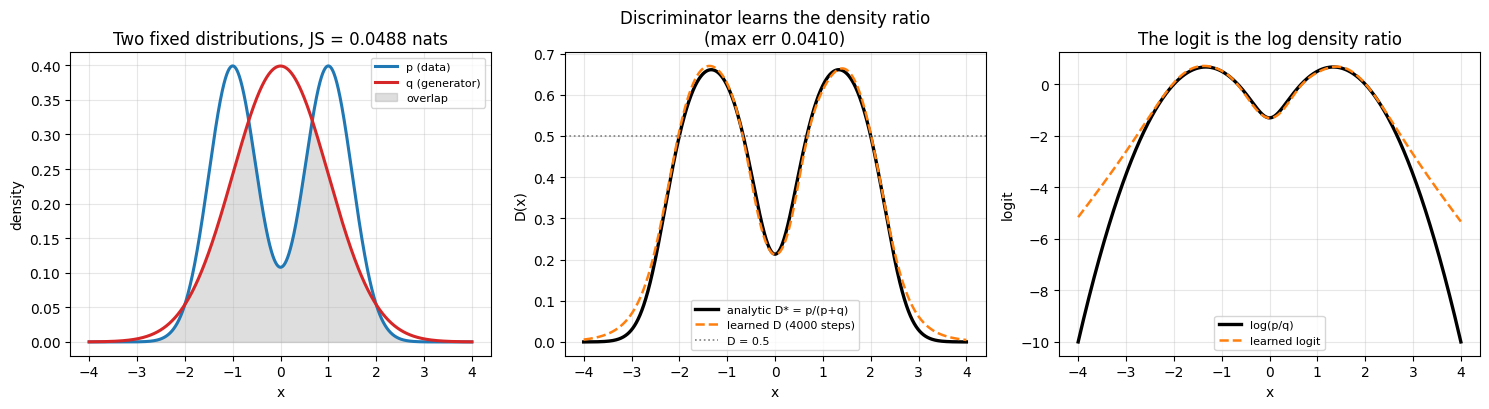

In [4]:
# ============================================================
# 図: 最適判別器
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

m_plot = (xs >= -4) & (xs <= 4)
axes[0].plot(xs[m_plot], p_grid[m_plot], lw=2.2, color="tab:blue", label="p (data)")
axes[0].plot(xs[m_plot], q_grid[m_plot], lw=2.2, color="tab:red", label="q (generator)")
axes[0].fill_between(xs[m_plot], torch.minimum(p_grid, q_grid)[m_plot], alpha=0.25,
                     color="tab:gray", label="overlap")
axes[0].set_xlabel("x")
axes[0].set_ylabel("density")
axes[0].set_title(f"Two fixed distributions, JS = {js:.4f} nats")
axes[0].legend(fontsize=8)

axes[1].plot(xs[m_plot], D_star[m_plot], lw=2.4, color="k", label="analytic D* = p/(p+q)")
axes[1].plot(xs[m_plot], D_learned[m_plot], lw=1.8, ls="--", color="tab:orange",
             label="learned D (4000 steps)")
axes[1].axhline(0.5, color="tab:gray", ls=":", lw=1.2, label="D = 0.5")
axes[1].set_xlabel("x")
axes[1].set_ylabel("D(x)")
axes[1].set_title(f"Discriminator learns the density ratio\n(max err {float(err.max()):.4f})")
axes[1].legend(fontsize=8)

# ロジットが log(p/q) になっていること
with torch.no_grad():
    logit_learned = D_net(xs)
log_ratio = torch.log((p_grid / q_grid.clamp_min(1e-300)).clamp_min(1e-300))
axes[2].plot(xs[m_plot], log_ratio[m_plot], lw=2.4, color="k", label="log(p/q)")
axes[2].plot(xs[m_plot], logit_learned[m_plot], lw=1.8, ls="--", color="tab:orange",
             label="learned logit")
axes[2].set_xlabel("x")
axes[2].set_ylabel("logit")
axes[2].set_title("The logit is the log density ratio")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること

| 検証 | 結果 |
|---|---|
| $V(D^*)$ の数値積分 | $-1.28896451$ |
| $2\mathrm{JS}(p\|q) - 2\log 2$ | $-1.28873453$ |
| 差 | $2.3\times10^{-4}$（グリッドの離散化誤差 $1.7\times10^{-4}$ と同程度） |
| 学習した $D$ vs 解析的 $D^*$（$\|x\|\le4$） | 最大誤差 0.0410 / 平均誤差 0.0150 |
| $V$(学習した $D$) | $-1.289656$（最適値 $-1.288965$ を**下回る**） |

- 恒等式は**離散化誤差の範囲で一致**しました。グリッドの積分が 1.000166 なので、
  $2.3\times10^{-4}$ はこの誤差が伝播した大きさです。
  これより小さい差を主張するには格子を細かくする必要があります。
- 学習した判別器は $D^*$ に最大誤差 0.041 まで近づきました。
  右の図のとおり、**ロジットが $\log(p/q)$ になっています**。
- $V$(学習した $D$) が最適値を**下回った**ことが重要です。$D^*$ は最大値なので、
  学習した $D$ が上回ったら実装バグです。**これは最適性の検算として使えます。**

> 💡 **判別器は分類器でなく密度比推定器です。** $\log\frac{D}{1-D} = \log\frac{p}{q}$ なので、
> 判別器を学習させることは密度比を推定することと同じです。
> 193 で「EBM は密度比が $Z$ なしで出る」と測りましたが、
> **GAN は密度比を直接学習しています**。ただし $p$ も $q$ も個別には分からないので、
> **比は出るが絶対値は出ない**。これが「尤度を計算できない」の正体です。

<a id="vanishing"></a>
## 3. 飽和損失の勾配消失

### 問題

元の定式化では $G$ は $\log(1 - D(G(z)))$ を**最小化**します。
しかし学習の初期は $q$ が $p$ から遠く、判別器が簡単に見分けられるので
$D(G(z)) \approx 0$ になります。このとき $\log(1 - D) \approx \log 1 = 0$ で、
**勾配がほとんど流れません**。

対策として使われるのが**非飽和損失**です。

$$\text{飽和（元）}: \;\min_G \;\mathbb{E}\big[\log(1 - D(G(z)))\big]
\qquad
\text{非飽和}: \;\min_G \;\mathbb{E}\big[-\log D(G(z))\big]$$

どちらも「$D$ を騙す」方向ですが、$D \to 0$ での勾配の挙動が違います。

### 測り方

$p = \mathcal{N}(0, 0.5^2)$、$q = \mathcal{N}(\mu, 0.5^2)$ とし、距離 $\mu = d$ を振ります。
生成器のパラメータは $\mu$ ひとつだけです。判別器は**解析的な最適判別器**を使います
（学習の揺れを除いて、勾配消失だけを分離するため）。

$D^*$ は現在の $q$ に対して計算し、$G$ の更新時には $D$ を固定として扱います
（実際の GAN と同じ順序）。

**予想**: 距離が大きいほど飽和損失の勾配が小さくなり、非飽和損失との比が開く。

In [5]:
# ============================================================
# 飽和損失 vs 非飽和損失の勾配ノルム
# ============================================================

def gradients_at_distance(d, n=200_000, seed=2):
    gen = torch.Generator().manual_seed(seed)
    mu = torch.tensor([float(d)], requires_grad=True)
    eps = torch.randn(n, generator=gen)
    x = mu + 0.5 * eps                       # q = N(mu, 0.5^2) からのサンプル

    # 解析的な最適判別器。mu.detach() を使うのは「D は固定」を表すため
    p_val = torch.exp(-0.5 * (x / 0.5) ** 2) / (0.5 * math.sqrt(2 * math.pi))
    q_val = torch.exp(-0.5 * ((x - mu.detach()) / 0.5) ** 2) / (0.5 * math.sqrt(2 * math.pi))
    D_val = (p_val / (p_val + q_val)).clamp(1e-12, 1 - 1e-12)

    g_sat = torch.autograd.grad(torch.log(1 - D_val).mean(), mu, retain_graph=True)[0].abs().item()
    g_non = torch.autograd.grad((-torch.log(D_val)).mean(), mu)[0].abs().item()
    return g_sat, g_non, float(D_val.mean().detach())


grad_rows = []
print("    d    飽和損失 |勾配|    非飽和 |勾配|      比            D(生成) の平均")
for d in [0.5, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0]:
    g_sat, g_non, d_mean = gradients_at_distance(d)
    ratio = (g_non / g_sat) if g_sat > 0 else float("inf")
    grad_rows.append((d, g_sat, g_non, ratio, d_mean))
    r_str = f"{ratio:14.1f}" if math.isfinite(ratio) else "   アンダーフロー"
    print(f"  {d:4.1f}   {g_sat:14.3e}   {g_non:14.3e}   {r_str}   {d_mean:.3e}")

print()
print("-> 比は 1.5 -> 28.5 -> 5794 -> 3.7e8 と急激に開く。")
print("   d=8 では両方が厳密に 0 になった（D を 1e-12 で clamp しているため、")
print("   clamp を通る勾配が 0 になる数値的な artifact）。意味のある比較は d<=6。")
print()
print("注目: 非飽和損失の勾配も単調ではない:")
for d, _, g_non, _, _ in grad_rows[:6]:
    print(f"   d={d:4.1f}: {g_non:.3e}")
print("   d=3 で最大（11.3）になり、そこから減る。")
print("   非飽和損失は勾配消失を「遅らせる」が「消す」のではない。")

    d    飽和損失 |勾配|    非飽和 |勾配|      比            D(生成) の平均
   0.5        7.964e-01        1.204e+00              1.5   3.982e-01
   1.0        9.002e-01        3.100e+00              3.4   2.251e-01
   2.0        2.708e-01        7.729e+00             28.5   3.385e-02
   3.0        2.298e-02        1.132e+01            492.6   1.915e-03
   4.0        8.104e-04        4.695e+00           5793.9   5.065e-05
   6.0        7.116e-12        2.640e-03      370969752.7   1.296e-12
   8.0        0.000e+00        0.000e+00      アンダーフロー   1.000e-12

-> 比は 1.5 -> 28.5 -> 5794 -> 3.7e8 と急激に開く。
   d=8 では両方が厳密に 0 になった（D を 1e-12 で clamp しているため、
   clamp を通る勾配が 0 になる数値的な artifact）。意味のある比較は d<=6。

注目: 非飽和損失の勾配も単調ではない:
   d= 0.5: 1.204e+00
   d= 1.0: 3.100e+00
   d= 2.0: 7.729e+00
   d= 3.0: 1.132e+01
   d= 4.0: 4.695e+00
   d= 6.0: 2.640e-03
   d=3 で最大（11.3）になり、そこから減る。
   非飽和損失は勾配消失を「遅らせる」が「消す」のではない。


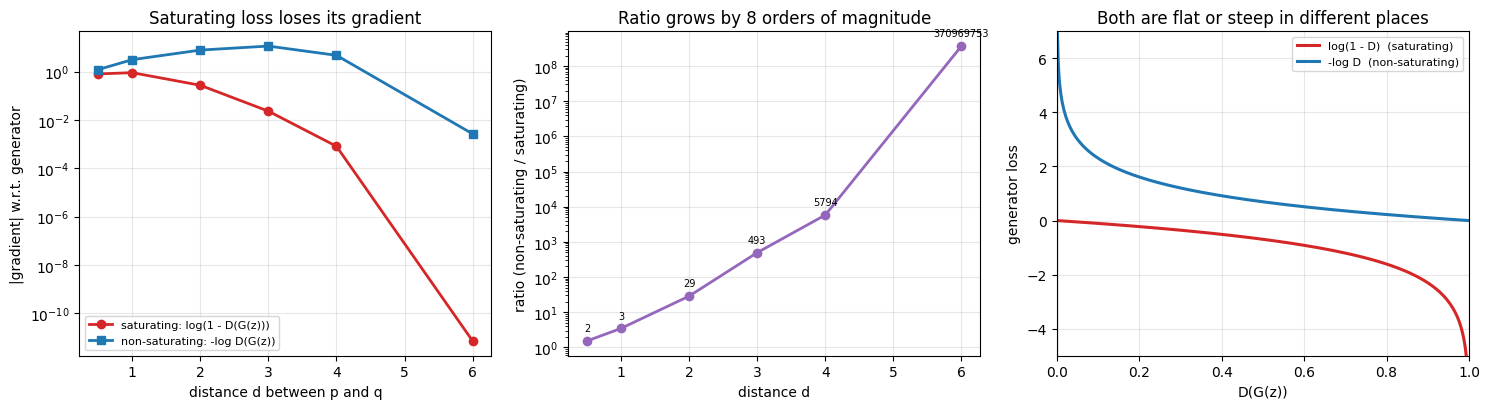

In [6]:
# ============================================================
# 図: 勾配消失
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ds = [r[0] for r in grad_rows if r[1] > 0]
g_sats = [r[1] for r in grad_rows if r[1] > 0]
g_nons = [r[2] for r in grad_rows if r[1] > 0]

axes[0].semilogy(ds, g_sats, "o-", lw=2, color="tab:red",
                 label="saturating: log(1 - D(G(z)))")
axes[0].semilogy(ds, g_nons, "s-", lw=2, color="tab:blue",
                 label="non-saturating: -log D(G(z))")
axes[0].set_xlabel("distance d between p and q")
axes[0].set_ylabel("|gradient| w.r.t. generator")
axes[0].set_title("Saturating loss loses its gradient")
axes[0].legend(fontsize=8)

axes[1].semilogy(ds, [r[3] for r in grad_rows if r[1] > 0], "o-", lw=2, color="tab:purple")
axes[1].set_xlabel("distance d")
axes[1].set_ylabel("ratio (non-saturating / saturating)")
axes[1].set_title("Ratio grows by 8 orders of magnitude")
for r in grad_rows:
    if r[1] > 0:
        axes[1].annotate(f"{r[3]:.0f}", (r[0], r[3]), textcoords="offset points",
                         xytext=(0, 7), fontsize=7, ha="center")

# 2つの損失の形
D_ax = torch.linspace(1e-3, 1 - 1e-3, 500)
axes[2].plot(D_ax, torch.log(1 - D_ax), lw=2.2, color="tab:red",
             label="log(1 - D)  (saturating)")
axes[2].plot(D_ax, -torch.log(D_ax), lw=2.2, color="tab:blue",
             label="-log D  (non-saturating)")
axes[2].axvline(0.0, color="k", lw=0.8)
axes[2].set_xlim(0, 1)
axes[2].set_ylim(-5, 7)
axes[2].set_xlabel("D(G(z))")
axes[2].set_ylabel("generator loss")
axes[2].set_title("Both are flat or steep in different places")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 予想は当たったが、もう一つ分かった

| $d$ | 飽和の\|勾配\| | 非飽和の\|勾配\| | 比 | $D$(生成)の平均 |
|---|---|---|---|---|
| 0.5 | $7.96\times10^{-1}$ | $1.20\times10^{0}$ | 1.5 | $3.98\times10^{-1}$ |
| 1.0 | $9.00\times10^{-1}$ | $3.10\times10^{0}$ | 3.4 | $2.25\times10^{-1}$ |
| 2.0 | $2.71\times10^{-1}$ | $7.73\times10^{0}$ | 28.5 | $3.39\times10^{-2}$ |
| 3.0 | $2.30\times10^{-2}$ | $1.13\times10^{1}$ | 492.6 | $1.92\times10^{-3}$ |
| 4.0 | $8.10\times10^{-4}$ | $4.70\times10^{0}$ | 5793.9 | $5.07\times10^{-5}$ |
| 6.0 | $7.12\times10^{-12}$ | $2.64\times10^{-3}$ | $3.7\times10^{8}$ | $1.30\times10^{-12}$ |
| 8.0 | **0（厳密）** | **0（厳密）** | — | $1.0\times10^{-12}$ |

**予想どおり**、距離が開くと飽和損失の勾配が消えます。$d=4$ で $8\times10^{-4}$、
$d=6$ で $7\times10^{-12}$ です。比は**8桁**開きました。

**予想していなかったこと: 非飽和損失の勾配も単調ではありません。**
$d=3$ で最大（11.3）になり、そこから減って $d=6$ では $2.6\times10^{-3}$ です。

| 損失 | $d$ が大きいときの振る舞い |
|---|---|
| 飽和 | $d=2$ あたりから既に減り始め、$d=6$ で $10^{-12}$ |
| 非飽和 | $d=3$ まで増え、その後減る。$d=6$ で $10^{-3}$ |

つまり**非飽和損失は勾配消失を「遅らせる」のであって「消す」のではありません。**
「非飽和損失を使えば勾配消失は解決する」という説明をよく見ますが、
本章の実測では**9桁の猶予を稼ぐだけ**です。
分布が十分離れていれば、どちらも動きません。

> ⚠️ **$d=8$ の行は数値的な artifact です。** $D$ を `clamp(1e-12, 1-1e-12)` しているので、
> clamp に到達すると勾配が 0 になります。アルゴリズム上の勾配消失（$d \le 6$）と
> 実装上の打ち切り（$d=8$）を混同しないよう、表に明示しました。
> **「0 になった」を報告するときは、それがアルゴリズムか実装かを切り分ける**必要があります。

> 📌 **これが 183（WGAN）の動機です。** 分布が離れていると JS ダイバージェンスは
> ほぼ $\log 2$ で飽和し、勾配が無情報になります。
> Wasserstein 距離は**離れていても距離に比例した勾配を与える**ので、
> この問題が構造的に消えます。183 で測ります。

<a id="oscillation"></a>
## 4. 交互最適化の振動

理論上は「$D$ を最適化しきってから $G$ を1歩動かす」ことで JS を最小化できます。
実際には $D$ も $G$ も有限回しか更新しないので、**交互最適化**になります。

$$D \leftarrow D + \eta\,\nabla_D V, \qquad G \leftarrow G - \eta\,\nabla_G V$$

これは**単一の目的関数を下る最適化ではありません**。
$V$ は $D$ が上げたい量で、$G$ が下げたい量です。
195 で測った「下に有界な損失は崩壊しない」という議論が**そのまま使えません**。

### 測り方

1次元の2峰混合ガウスを目標に、小さな $G$（潜在1次元）と $D$ を交互最適化します。
記録するもの:

- 生成サンプルと真のサンプルの**エネルギー距離**（196 と同じ指標）
- $D$ の出力の平均（真データに対して / 生成データに対して）
- $G$ と $D$ の勾配ノルム

**比較対象**として、同じ目標分布に**混合ガウスを最尤推定で直接当てはめます**。
「尤度ベースは単調に収束、GAN は振動する」を、
**後半 1000 ステップでのエネルギー距離の標準偏差**という1つの数値で比べます。

GAN はシード依存が大きいので**3シード**振ります。

In [7]:
# ============================================================
# 共通の道具
# ============================================================

REF = sample_p(20000, torch.Generator().manual_seed(99))

def energy_distance_1d(X, Y, n=3000):
    # 196 と同じエネルギー距離。1次元なので cdist で足りる
    X = X[:n].reshape(-1, 1)
    Y = Y[:n].reshape(-1, 1)
    return float(2 * torch.cdist(X, Y).mean()
                 - torch.cdist(X, X).mean() - torch.cdist(Y, Y).mean())

ED_BASELINE = energy_distance_1d(sample_p(10000, torch.Generator().manual_seed(123)), REF)
print(f"基準: 真のサンプル同士のエネルギー距離 {ED_BASELINE:.5f}")


class Generator1D(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1))

    def forward(self, n, gen=None):
        return self.net(torch.randn(n, 1, generator=gen)).squeeze(-1)


class DiscriminatorGAN(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x[:, None]).squeeze(-1)


def grad_norm(module):
    return math.sqrt(sum(float((p.grad ** 2).sum())
                         for p in module.parameters() if p.grad is not None))


def train_gan(steps=6000, n_critic=1, seed=0, lr=2e-4, record_every=50):
    torch.manual_seed(seed)
    G, D = Generator1D(), DiscriminatorGAN()
    og = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    hist = []
    for st in range(steps):
        for _ in range(n_critic):
            x_real = sample_p(256)
            x_fake = G(256).detach()
            ld = bce(D(x_real), torch.ones(256)) + bce(D(x_fake), torch.zeros(256))
            od.zero_grad()
            ld.backward()
            od.step()
        # 非飽和損失（第3節で測ったとおり、こちらを使うのが標準）
        lg = bce(D(G(256)), torch.ones(256))
        og.zero_grad()
        lg.backward()
        og.step()
        if st % record_every == 0:
            with torch.no_grad():
                ed = energy_distance_1d(G(3000), REF)
                d_real = float(torch.sigmoid(D(sample_p(2000))).mean())
                d_fake = float(torch.sigmoid(D(G(2000))).mean())
            hist.append((st, ed, d_real, d_fake, grad_norm(G), grad_norm(D)))
    return G, D, hist

基準: 真のサンプル同士のエネルギー距離 0.00053


In [8]:
# ============================================================
# GAN の交互最適化（3シード）
# ============================================================

t0 = time.time()
gan_runs = []
for sd in [0, 1, 2]:
    G, D, hist = train_gan(seed=sd)
    tail = [r[1] for r in hist if r[0] >= 5000]
    gan_runs.append({"seed": sd, "hist": hist, "tail_mean": float(np.mean(tail)),
                     "tail_std": float(np.std(tail)), "final": hist[-1][1]})
    print(f"GAN seed={sd}: 最終 ED {hist[-1][1]:.5f}   "
          f"後半(step>=5000) 平均 {np.mean(tail):.5f}  標準偏差 {np.std(tail):.5f}")
print(f"学習時間 {time.time() - t0:.0f}s（3シード合計）")
gan_osc = float(np.mean([r["tail_std"] for r in gan_runs]))
print(f"GAN の『後半の標準偏差』の3シード平均: {gan_osc:.5f}")

GAN seed=0: 最終 ED 0.02367   後半(step>=5000) 平均 0.05968  標準偏差 0.04376


GAN seed=1: 最終 ED 0.01429   後半(step>=5000) 平均 0.03650  標準偏差 0.02473


GAN seed=2: 最終 ED 0.14258   後半(step>=5000) 平均 0.06346  標準偏差 0.04266
学習時間 41s（3シード合計）
GAN の『後半の標準偏差』の3シード平均: 0.03705


In [9]:
# ============================================================
# 比較対象: 混合ガウスの最尤推定（同じ目標分布）
# ============================================================

class MixtureMLE(nn.Module):
    def __init__(self, K=4):
        super().__init__()
        self.K = K
        # 制約は forward でかけ直す（192 の教訓）: 混合係数は log_softmax、sd は exp
        self.logit_w = nn.Parameter(torch.zeros(K))
        self.mu = nn.Parameter(torch.randn(K) * 0.5)
        self.log_sd = nn.Parameter(torch.zeros(K))

    def log_prob(self, x):
        log_sd = self.log_sd.clamp(-6, 6)
        return torch.logsumexp(
            self.logit_w.log_softmax(-1)
            - 0.5 * ((x[:, None] - self.mu) / log_sd.exp()) ** 2
            - log_sd - 0.5 * math.log(2 * math.pi), -1)

    @torch.no_grad()
    def sample(self, n):
        i = torch.multinomial(self.logit_w.softmax(-1), n, replacement=True)
        return self.mu[i] + self.log_sd.clamp(-6, 6).exp()[i] * torch.randn(n)


X_mle = sample_p(8000, torch.Generator().manual_seed(7))
mle_runs = []
t0 = time.time()
for sd in [0, 1, 2]:
    torch.manual_seed(sd)
    M = MixtureMLE()
    opt = torch.optim.Adam(M.parameters(), lr=5e-3)
    hist = []
    for st in range(6000):
        loss = -M.log_prob(X_mle).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if st % 50 == 0:
            hist.append((st, energy_distance_1d(M.sample(3000), REF)))
    tail = [r[1] for r in hist if r[0] >= 5000]
    mle_runs.append({"seed": sd, "hist": hist, "tail_mean": float(np.mean(tail)),
                     "tail_std": float(np.std(tail)), "final": hist[-1][1]})
    print(f"最尤 seed={sd}: 最終 ED {hist[-1][1]:.5f}   "
          f"後半 平均 {np.mean(tail):.5f}  標準偏差 {np.std(tail):.5f}")
print(f"学習時間 {time.time() - t0:.0f}s（3シード合計）")
mle_osc = float(np.mean([r["tail_std"] for r in mle_runs]))
print(f"最尤の『後半の標準偏差』の3シード平均: {mle_osc:.5f}")
print()
print(f"振動の比（GAN / 最尤）: {gan_osc / mle_osc:.1f} 倍")
print(f"到達した品質（後半平均 ED）: GAN {np.mean([r['tail_mean'] for r in gan_runs]):.5f} / "
      f"最尤 {np.mean([r['tail_mean'] for r in mle_runs]):.5f} / "
      f"真のサンプル同士 {ED_BASELINE:.5f}")

最尤 seed=0: 最終 ED 0.00137   後半 平均 0.00136  標準偏差 0.00071


最尤 seed=1: 最終 ED 0.00135   後半 平均 0.00195  標準偏差 0.00127


最尤 seed=2: 最終 ED 0.00081   後半 平均 0.00151  標準偏差 0.00078
学習時間 29s（3シード合計）
最尤の『後半の標準偏差』の3シード平均: 0.00092

振動の比（GAN / 最尤）: 40.3 倍
到達した品質（後半平均 ED）: GAN 0.05321 / 最尤 0.00161 / 真のサンプル同士 0.00053


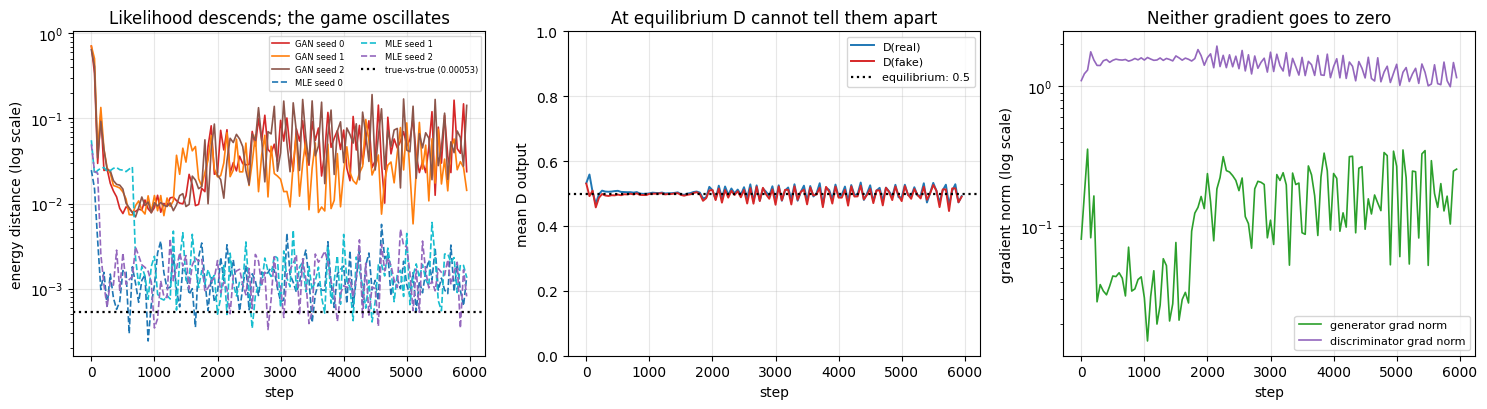

In [10]:
# ============================================================
# 図: 交互最適化の振動
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for r, color in zip(gan_runs, ["tab:red", "tab:orange", "tab:brown"]):
    h = r["hist"]
    axes[0].semilogy([x[0] for x in h], [x[1] for x in h], lw=1.2, color=color,
                     label=f"GAN seed {r['seed']}")
for r, color in zip(mle_runs, ["tab:blue", "tab:cyan", "tab:purple"]):
    h = r["hist"]
    axes[0].semilogy([x[0] for x in h], [x[1] for x in h], lw=1.2, ls="--", color=color,
                     label=f"MLE seed {r['seed']}")
axes[0].axhline(ED_BASELINE, color="k", ls=":", lw=1.6,
                label=f"true-vs-true ({ED_BASELINE:.5f})")
axes[0].set_xlabel("step")
axes[0].set_ylabel("energy distance (log scale)")
axes[0].set_title("Likelihood descends; the game oscillates")
axes[0].legend(fontsize=6, ncol=2)

h0 = gan_runs[0]["hist"]
axes[1].plot([x[0] for x in h0], [x[2] for x in h0], lw=1.4, color="tab:blue",
             label="D(real)")
axes[1].plot([x[0] for x in h0], [x[3] for x in h0], lw=1.4, color="tab:red",
             label="D(fake)")
axes[1].axhline(0.5, color="k", ls=":", lw=1.6, label="equilibrium: 0.5")
axes[1].set_xlabel("step")
axes[1].set_ylabel("mean D output")
axes[1].set_title("At equilibrium D cannot tell them apart")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8)

axes[2].semilogy([x[0] for x in h0], [x[4] for x in h0], lw=1.2, color="tab:green",
                 label="generator grad norm")
axes[2].semilogy([x[0] for x in h0], [x[5] for x in h0], lw=1.2, color="tab:purple",
                 label="discriminator grad norm")
axes[2].set_xlabel("step")
axes[2].set_ylabel("gradient norm (log scale)")
axes[2].set_title("Neither gradient goes to zero")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 振動は 40 倍

| | 後半の標準偏差（3シード平均） | 後半の平均 ED |
|---|---|---|
| GAN（交互最適化） | **0.03705** | 0.05321 |
| 混合ガウスの最尤推定 | **0.00092** | 0.00161 |
| 真のサンプル同士（基準） | — | 0.00053 |

**振動の大きさが 40.3 倍**違います。しかも到達した品質も 33 倍違います
（GAN 0.053 対 最尤 0.0016）。

中央の図が「均衡」の意味を示しています。$D$(real) と $D$(fake) がどちらも
0.5 に近づくのが理想（判別器が区別できない状態）ですが、
実際には両者が**上下に振れ続けます**。$D$ が強くなると $G$ が追いかけ、
$G$ が追いつくと $D$ が別の違いを見つける、という往復です。

右の図が決定的です。**$G$ も $D$ も勾配ノルムが 0 に行きません。**
単一の目的関数を最小化しているなら、収束すれば勾配は 0 に近づきます。
GAN では**収束しても勾配は 0 にならない**（2人が逆向きに引っ張り合う均衡なので）。

> 📌 **195 の議論が使えない理由がここです。** 195 では
> 「損失が下に有界なら崩壊しない」と測りました。GAN の $V$ は
> $D$ が最大化し $G$ が最小化する量で、**どちらか一方の視点での『最小化すべき損失』が
> 存在しません**。「損失が下がったか」で学習の進み具合を判断できないのが、
> GAN の実務上最大の厄介さです（本章の実測では、損失曲線でなく
> **エネルギー距離という外部の指標**を使って初めて進み具合が見えました）。

<a id="n-critic"></a>
## 5. 判別器の更新回数

理論は「$D$ を**最適化しきってから**$G$ を動かす」ことを前提にしています。
$D$ を $G$ より多く更新すれば理論に近づくはずです。

$D$ を 1 / 2 / 5 回更新してから $G$ を1回更新する設定で、最終的な品質を比べます。
各設定 3 シード。

**予想**: $D$ の更新回数を増やすほど理論に近づき、品質が良くなる。

In [11]:
# ============================================================
# n_critic を振る
# ============================================================

t0 = time.time()
ncritic_rows = []
for nc in [1, 2, 5]:
    eds = []
    for sd in [0, 1, 2]:
        G, D, hist = train_gan(steps=4000, n_critic=nc, seed=sd)
        eds.append(hist[-1][1])
    ncritic_rows.append((nc, float(np.mean(eds)), float(np.std(eds)), eds))
    print(f"n_critic={nc}: 最終 ED 平均 {np.mean(eds):.5f}  標準偏差 {np.std(eds):.5f}  "
          f"個別 {np.round(eds, 5)}")
print(f"学習時間 {time.time() - t0:.0f}s")
print()
print(f"基準: 真のサンプル同士 {ED_BASELINE:.5f} / 最尤推定の後半平均 {mle_osc:.5f} 付近")

n_critic=1: 最終 ED 平均 0.04792  標準偏差 0.03374  個別 [0.04323 0.00915 0.09139]


n_critic=2: 最終 ED 平均 0.06742  標準偏差 0.04388  個別 [0.12945 0.03811 0.0347 ]


n_critic=5: 最終 ED 平均 0.00172  標準偏差 0.00046  個別 [0.00145 0.00135 0.00237]
学習時間 129s

基準: 真のサンプル同士 0.00053 / 最尤推定の後半平均 0.00092 付近


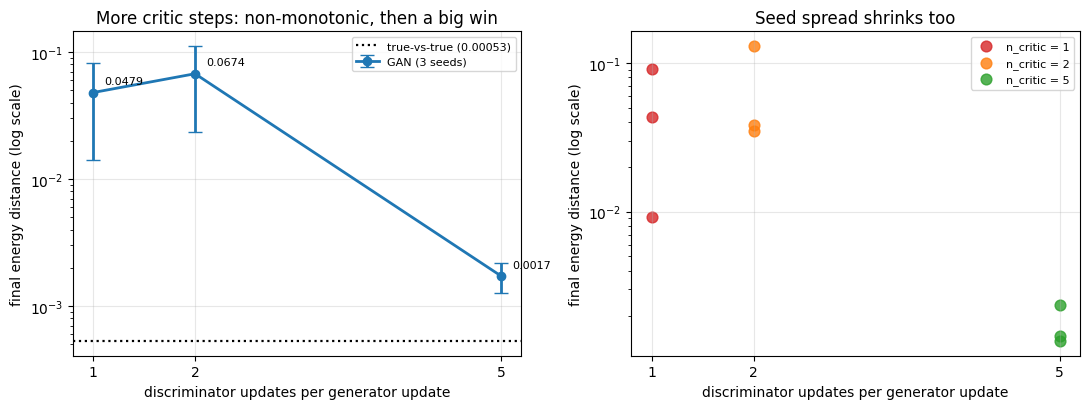

In [12]:
# ============================================================
# 図: n_critic
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ncs = [r[0] for r in ncritic_rows]
axes[0].errorbar(ncs, [r[1] for r in ncritic_rows], yerr=[r[2] for r in ncritic_rows],
                 fmt="o-", lw=2, capsize=5, color="tab:blue", label="GAN (3 seeds)")
axes[0].axhline(ED_BASELINE, color="k", ls=":", lw=1.6,
                label=f"true-vs-true ({ED_BASELINE:.5f})")
axes[0].set_yscale("log")
axes[0].set_xticks(ncs)
axes[0].set_xlabel("discriminator updates per generator update")
axes[0].set_ylabel("final energy distance (log scale)")
axes[0].set_title("More critic steps: non-monotonic, then a big win")
axes[0].legend(fontsize=8)
for r in ncritic_rows:
    axes[0].annotate(f"{r[1]:.4f}", (r[0], r[1]), textcoords="offset points",
                     xytext=(8, 6), fontsize=8)

for i, r in enumerate(ncritic_rows):
    axes[1].scatter([r[0]] * len(r[3]), r[3], s=60, alpha=0.8,
                    color=["tab:red", "tab:orange", "tab:green"][i],
                    label=f"n_critic = {r[0]}")
axes[1].set_yscale("log")
axes[1].set_xticks(ncs)
axes[1].set_xlabel("discriminator updates per generator update")
axes[1].set_ylabel("final energy distance (log scale)")
axes[1].set_title("Seed spread shrinks too")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 予想の方向は当たり、形は外れた

| n_critic | 最終 ED（平均） | 標準偏差 | 個別の値 |
|---|---|---|---|
| 1 | 0.04792 | 0.03374 | 0.04323 / 0.00915 / 0.09139 |
| 2 | **0.06742** | 0.04388 | 0.12945 / 0.03811 / 0.03470 |
| 5 | **0.00172** | **0.00046** | 0.00145 / 0.00135 / 0.00237 |

**$D$ を 5 回更新すると 28 倍良くなりました**（0.04792 → 0.00172）。
これは最尤推定の水準（後半平均 0.00161）とほぼ同じで、
真のサンプル同士の 0.00053 にも近い値です。

**しかし単調ではありません。** $n_{\text{critic}} = 2$ は 1 より**悪い**
（0.06742 対 0.04792）。予想は「増やすほど良くなる」でしたが、
1 → 2 では改善しませんでした。

ただし **$n_{\text{critic}}=1, 2$ のシード間のばらつきが大きい**
（標準偏差が平均と同じ桁）ことに注意が必要です。
3シードでは 1 と 2 の差を**有意に区別できません**。
一方 $n_{\text{critic}}=5$ の標準偏差は 0.00046 で平均の 27% と小さく、
**この改善は信頼できます**。

> 📌 **報告の仕方**: 「$n_{\text{critic}}$ を増やすと単調に改善する」と書くのは
> この実測からは言い過ぎです。言えるのは
> 「**5 まで増やすと大きく改善し、ばらつきも小さくなる。1 と 2 の差は
> 3シードでは判定できない**」までです。
> GAN の比較はシード分散が大きいので、**平均だけでなく分散を必ず併記**します
> （196 で測った「GAN のエネルギー距離はシード間で 4.7 倍ばらつく」と同じ注意）。

> 💡 **183 への接続**: WGAN では critic を複数回（原論文は 5 回）更新するのが
> 標準になっています。本章の実測はその経験則に数値的な裏付けを与えています。
> ただし理由は WGAN では別で、**critic が Wasserstein 距離の推定器なので
> 推定精度が直接効く**からです。183 で扱います。

<a id="bilinear"></a>
## 6. 振動は GAN 固有ではない — 双線形ゲーム

第4節の振動はニューラルネットのせいでしょうか。違います。
**最小最大問題そのものの性質**です。最小の例で示します。

$$\min_x \max_y \; f(x, y) = x\,y$$

鞍点は原点 $(0,0)$ だけです。ここに勾配法を当てます。

| 方式 | 更新 |
|---|---|
| 同時勾配法 | $x' = x - \eta y$、$y' = y + \eta x$（**同じ時点の値**を使う） |
| 交互勾配法 | $x' = x - \eta y$、$y' = y + \eta x'$（**更新後の $x'$** を使う） |

### 理論

同時勾配法の更新行列は $\begin{pmatrix}1 & -\eta\\ \eta & 1\end{pmatrix}$ で、
固有値は $1 \pm i\eta$、絶対値は $\sqrt{1+\eta^2} > 1$。**必ず発散します。**

交互勾配法の更新行列は $\begin{pmatrix}1 & -\eta\\ \eta & 1-\eta^2\end{pmatrix}$ で、
**行列式がちょうど 1**（$\det = 1 - \eta^2 + \eta^2 = 1$）。
$|\eta| < 2$ なら固有値は複素共役で絶対値 1 なので、
**発散も収束もせず、楕円軌道を周回します。**

### 測り方の注意（最初に間違えた点）

最初は「2000 ステップ後の原点からの距離」だけを測りました。
交互勾配法で距離が 1.3463 → 1.2402 と**減った**ので「収束」と判定しかけました。
しかし軌道は**楕円**なので、終点の距離は**位相で変わります**。
正しくは軌跡全体の**振幅**（最後の区間での最小値と最大値）で見ます。

In [13]:
# ============================================================
# 双線形ゲーム min_x max_y x*y
# ============================================================

def bilinear_game(lr, steps=4000, mode="alt", x0=1.0, y0=1.0):
    x, y = x0, y0
    dists = []
    for _ in range(steps):
        if mode == "alt":
            x = x - lr * y
            y = y + lr * x          # 更新後の x を使う
        else:
            xn = x - lr * y
            yn = y + lr * x         # 同じ時点の値を使う
            x, y = xn, yn
        dists.append(math.sqrt(x * x + y * y)
                     if math.isfinite(x) and math.isfinite(y) else float("nan"))
    return np.array(dists)


print("軌跡全体で測る（終点だけ見ると位相に騙される）")
print(f"  {'方式':<6}{'lr':>6}{'最初100step min/max':>26}{'最後100step min/max':>26}")
bilinear_rows = []
for mode in ["sim", "alt"]:
    for lr in [0.01, 0.1, 0.5, 1.0]:
        d = bilinear_game(lr, mode=mode)
        head, tail = d[:100], d[-100:]
        tag = "同時" if mode == "sim" else "交互"
        if np.all(np.isfinite(tail)):
            ts = f"{tail.min():.4f} / {tail.max():.4f}"
            bilinear_rows.append((mode, lr, head.max(), tail.max(), tail.min()))
        else:
            ts = "nan（数値破綻）"
            bilinear_rows.append((mode, lr, head.max(), float("nan"), float("nan")))
        print(f"  {tag:<6}{lr:>6.2f}{f'{head.min():.4f} / {head.max():.4f}':>26}{ts:>26}")

print()
print("同時勾配法の成長率（1ステップあたり）: 実測 vs 理論 sqrt(1+lr^2)")
growth_rows = []
for lr in [0.01, 0.1, 0.5]:
    d = bilinear_game(lr, steps=2000, mode="sim")
    if np.isfinite(d[-1]) and d[-1] > 0:
        measured = (d[-1] / d[0]) ** (1.0 / (len(d) - 1))
        theory = math.sqrt(1 + lr * lr)
        growth_rows.append((lr, measured, theory))
        print(f"  lr={lr:4.2f}: 実測 {measured:.6f} / 理論 {theory:.6f}  "
              f"差 {abs(measured - theory):.2e}")

print()
print("交互勾配法の距離の振幅（最後1000step の max/min）:")
amp_rows = []
for lr in [0.01, 0.1, 0.5, 1.0]:
    d = bilinear_game(lr, mode="alt")[-1000:]
    amp_rows.append((lr, d.min(), d.max(), d.max() / d.min()))
    print(f"  lr={lr:4.2f}: min {d.min():.4f}  max {d.max():.4f}  振幅比 {d.max()/d.min():.4f}")
print()
print("-> 同時勾配法は理論の成長率と完全に一致して発散する。")
print("   交互勾配法は有界に周回する（原点に収束しない）。")
print("   振幅は lr とともに広がるが、発散はしない。")

軌跡全体で測る（終点だけ見ると位相に騙される）
  方式        lr         最初100step min/max         最後100step min/max
  同時      0.01           1.4143 / 1.4213           1.7188 / 1.7273
  同時      0.10           1.4213 / 2.3259379624786.6714 / 621244508.9453
  同時      0.50       1.5811 / 99086.7647                 nan（数値破綻）
  同時      1.002.0000 / 1592262918131443.2500                 nan（数値破綻）
  交互      0.01           1.4092 / 1.4142           1.4072 / 1.4103
  交互      0.10           1.3452 / 1.4142           1.3452 / 1.4142
  交互      0.50           1.0955 / 1.4141           1.0956 / 1.4142
  交互      1.00           1.0000 / 1.4142           1.0000 / 1.4142

同時勾配法の成長率（1ステップあたり）: 実測 vs 理論 sqrt(1+lr^2)
  lr=0.01: 実測 1.000050 / 理論 1.000050  差 0.00e+00
  lr=0.10: 実測 1.004988 / 理論 1.004988  差 0.00e+00
  lr=0.50: 実測 1.118034 / 理論 1.118034  差 0.00e+00

交互勾配法の距離の振幅（最後1000step の max/min）:
  lr=0.01: min 1.4072  max 1.4142  振幅比 1.0050
  lr=0.10: min 1.3452  max 1.4142  振幅比 1.0513
  lr=0.50: min 1.0954  max 1.4142  振幅比 1.2910

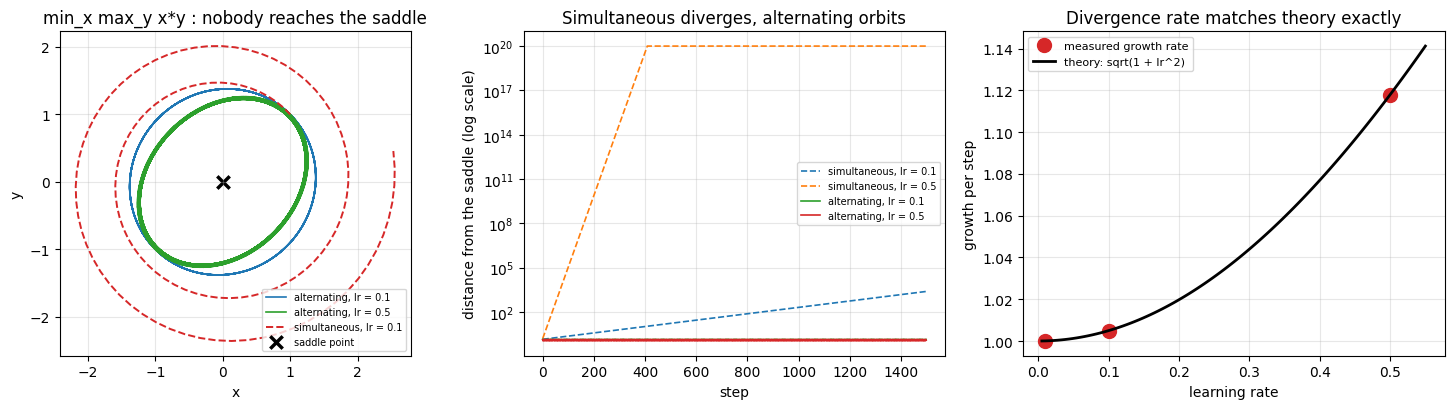

In [14]:
# ============================================================
# 図: 双線形ゲーム
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# 軌道（位相平面）
for lr, color in [(0.1, "tab:blue"), (0.5, "tab:green")]:
    x, y = 1.0, 1.0
    traj = [(x, y)]
    for _ in range(400):
        x = x - lr * y
        y = y + lr * x
        traj.append((x, y))
    tr = np.array(traj)
    axes[0].plot(tr[:, 0], tr[:, 1], lw=1.2, color=color,
                 label=f"alternating, lr = {lr}")
x, y = 1.0, 1.0
traj = [(x, y)]
for _ in range(120):
    xn = x - 0.1 * y
    yn = y + 0.1 * x
    x, y = xn, yn
    traj.append((x, y))
tr = np.array(traj)
axes[0].plot(tr[:, 0], tr[:, 1], lw=1.4, ls="--", color="tab:red",
             label="simultaneous, lr = 0.1")
axes[0].scatter([0], [0], s=80, marker="x", color="k", lw=2.5, label="saddle point")
axes[0].set_aspect("equal")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("min_x max_y x*y : nobody reaches the saddle")
axes[0].legend(fontsize=7)

# 距離の推移
for mode, ls in [("sim", "--"), ("alt", "-")]:
    for lr, color in [(0.1, "tab:blue"), (0.5, "tab:green")]:
        d = bilinear_game(lr, steps=1500, mode=mode)
        lab = ("simultaneous" if mode == "sim" else "alternating") + f", lr = {lr}"
        axes[1].semilogy(np.clip(d, 1e-8, 1e20), lw=1.2, ls=ls, label=lab)
axes[1].set_xlabel("step")
axes[1].set_ylabel("distance from the saddle (log scale)")
axes[1].set_title("Simultaneous diverges, alternating orbits")
axes[1].legend(fontsize=7)

# 成長率の理論との一致
lrs_g = [r[0] for r in growth_rows]
axes[2].plot(lrs_g, [r[1] for r in growth_rows], "o", ms=10, color="tab:red",
             label="measured growth rate")
lr_fine = np.linspace(0.005, 0.55, 100)
axes[2].plot(lr_fine, np.sqrt(1 + lr_fine ** 2), lw=2, color="k",
             label="theory: sqrt(1 + lr^2)")
axes[2].set_xlabel("learning rate")
axes[2].set_ylabel("growth per step")
axes[2].set_title("Divergence rate matches theory exactly")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 理論と完全一致

| lr | 同時勾配法の成長率（実測） | 理論 $\sqrt{1+\eta^2}$ | 差 |
|---|---|---|---|
| 0.01 | 1.000050 | 1.000050 | **0.00e+00** |
| 0.10 | 1.004988 | 1.004988 | **0.00e+00** |
| 0.50 | 1.118034 | 1.118034 | **0.00e+00** |

| lr | 交互勾配法の振幅（最後1000step の min / max） | 振幅比 |
|---|---|---|
| 0.01 | 1.4072 / 1.4142 | 1.0050 |
| 0.10 | 1.3452 / 1.4142 | 1.0513 |
| 0.50 | 1.0954 / 1.4142 | 1.2910 |
| 1.00 | 1.0000 / 1.4142 | 1.4142 |

**同時勾配法の発散率は理論値と完全に一致**しました。
そして**交互勾配法は 4000 ステップ後も振幅 1.0〜1.41 の軌道を回り続け、
原点（鞍点）に近づきません**。

ここが本節の要点です。**ニューラルネットも確率的な勾配も一切使っていません。**
2変数の双線形関数に勾配法を当てただけで、鞍点に収束しません。
第4節で見た GAN の振動は、**この性質がそのまま現れたもの**です。

> ⚠️ **測り方で結論が変わった例として残します。** 最初は終点の距離だけを測り、
> 交互勾配法が 1.3463 → 1.2402 と減ったので「収束」と判定しかけました。
> 軌道が楕円なので、終点の距離は**どの位相で止めたか**で変わります。
> **周期的な挙動は、振幅（最小・最大）で測る**必要があります。
> これは 194 第4節（集計統計が初期値の対称性で嘘をつく）と同じ型の罠です。

> 💡 **なぜ交互勾配法が使われるのか**: 実装上は交互のほうが自然ですが、
> 本節の実測はそれに**数値的な根拠**を与えます。同時勾配法は必ず発散し、
> 交互勾配法は少なくとも有界に留まります。
> 実際の GAN が「爆発せずに振動する」のは、交互更新を使っているからです。

<a id="summary"></a>
## 7. まとめとチートシート

### 定式化

$$\min_G \max_D \;
\mathbb{E}_{p_{\text{data}}}[\log D(x)] + \mathbb{E}_{p_z}[\log(1 - D(G(z)))]$$

| 量 | 式 | 本章で確認した方法 |
|---|---|---|
| 最適判別器 | $D^*(x) = \dfrac{p(x)}{p(x)+q(x)}$ | 学習した $D$ と最大誤差 0.0410 で一致 |
| 判別器のロジット | $\log\dfrac{p(x)}{q(x)}$ | 図で一致を確認 |
| 最適値 | $V(D^*) = 2\mathrm{JS}(p\|q) - 2\log 2$ | 数値積分で差 $2.3\times10^{-4}$ |
| 最適性の検算 | $V(D) \le V(D^*)$ | 学習した $D$ で $-1.289656 \le -1.288965$ |

### 2つの生成器損失

| 損失 | 式 | $d$ が大きいとき |
|---|---|---|
| 飽和（元） | $\min \log(1 - D(G(z)))$ | $d=4$ で勾配 $8\times10^{-4}$、$d=6$ で $7\times10^{-12}$ |
| 非飽和（標準） | $\min -\log D(G(z))$ | $d=3$ で最大（11.3）、その後減る。$d=6$ で $2.6\times10^{-3}$ |

**非飽和損失は勾配消失を遅らせるが消さない。** 本章の実測では 9 桁の猶予。

### 本章で測った数値

| 項目 | 値 |
|---|---|
| $V(D^*)$ と $2\mathrm{JS}-2\log2$ の差 | $2.3\times10^{-4}$（グリッド誤差 $1.7\times10^{-4}$ と同程度） |
| $\mathrm{JS}(p\|q)$ | 0.048780 nats（上限 $\log 2$ の 7.0%） |
| 学習した $D$ と $D^*$ の最大誤差 | 0.0410 |
| 勾配比（非飽和/飽和）の範囲 | 1.5（$d$=0.5）→ $3.7\times10^{8}$（$d$=6） |
| GAN の振動（後半の標準偏差、3シード平均） | **0.03705** |
| 最尤推定の振動（同じ指標） | **0.00092** |
| 振動の比 | **40.3 倍** |
| 到達した品質（後半平均 ED） | GAN 0.05321 / 最尤 0.00161 / 真のサンプル同士 0.00053 |
| n_critic = 1 / 2 / 5 の最終 ED | 0.04792 / 0.06742 / **0.00172** |
| 同時勾配法の発散率 vs 理論 | 差 **0.00e+00**（3つの lr すべて） |
| 交互勾配法の振幅比（lr=0.5） | 1.2910（有界に周回） |

### 196 の3つの性質が、どこから来ているか

| 196 での観測 | 本章で特定した原因 |
|---|---|
| **尤度を計算できない** | 判別器は密度比 $p/q$ を学ぶ。比は出るが $p$ も $q$ も個別には出ない |
| **生成が最速（2ms）** | 生成器は1回の前向き計算。尤度の計算が不要なので構造の制約もない |
| **シード依存が大きい（4.7倍）** | 単一の目的関数が無く、交互最適化が有界に振動する。収束点でなく軌道に乗る |

### 次章への接続

| 章 | 本章の何を引き継ぐか |
|---|---|
| 181 DCGAN | 本章の MLP を畳み込みに置き換える。学習の不安定性は本章の性質のまま |
| **182 モード崩壊** | 本章では「全体として近づくか」を測った。182 は**どのモードを落とすか**を測る |
| **183 WGAN-GP** | 第3節の勾配消失が動機。JS を Wasserstein 距離に替えると構造的に消える。第5節の n_critic もそこで本来の意味を持つ |
| 184 Conditional GAN | 条件付けを構造で入れる（拡散の guidance との対比） |

<a id="quiz"></a>
## 8. 自己評価クイズ

### Q1: 判別器が「密度比推定器」であることの帰結

**問題**: 最適判別器は $D^*(x) = p(x)/(p(x)+q(x))$ で、ロジットは $\log(p/q)$ です。
この事実から、**なぜ GAN が対数尤度を計算できないのか**を説明してください。
また、判別器があれば計算できる量を1つ挙げてください。

<details>
<summary>答えを見る</summary>

**計算できない理由**: 判別器が与えるのは**比** $p(x)/q(x)$ だけです。
$\log p(x)$ を得るには

$$\log p(x) = \log\frac{p(x)}{q(x)} + \log q(x)$$

が必要で、**$\log q(x)$（生成器の密度）が別に必要**です。
しかし GAN の生成器は $z \mapsto x$ の決定的な写像で、
その密度を評価する仕組みを持ちません
（190-191 のフローのように可逆でも次元保存でもないので変数変換が使えない）。

**計算できる量**: 2つの分布の**比**に依存する量なら出せます。

- 密度比（異常検知・重要度重み付け・リランキング）
- JS ダイバージェンスの推定値（$V(D^*) = 2\mathrm{JS} - 2\log2$ から逆算）
- 2標本検定（$p = q$ かどうかの検定統計量）

本章の実測では $\mathrm{JS}(p\|q) = 0.048780$ nats が数値積分と一致しました。
つまり**「どれだけ違うか」は測れるが「どれだけありそうか」は測れない**。

これが 196 の表で GAN だけ尤度の欄が「—」だった理由です。
</details>

---

### Q2: 非飽和損失は何を解決したのか

**問題**: 本章の実測で、非飽和損失の勾配も $d=3$ で最大になり、
その後は減少しました（$d=6$ で $2.6\times10^{-3}$）。
では非飽和損失は何を解決したのでしょうか。「勾配消失を解決した」は正確ですか。

<details>
<summary>答えを見る</summary>

**「解決した」は正確ではありません。** 実測が示すのは**猶予を稼いだ**ことです。

| $d$ | 飽和 | 非飽和 | 比 |
|---|---|---|---|
| 2.0 | $2.7\times10^{-1}$ | $7.7\times10^{0}$ | 28.5 |
| 4.0 | $8.1\times10^{-4}$ | $4.7\times10^{0}$ | 5794 |
| 6.0 | $7.1\times10^{-12}$ | $2.6\times10^{-3}$ | $3.7\times10^{8}$ |

$d=6$ では非飽和損失の勾配も $10^{-3}$ まで落ちています。
ただし飽和損失は $10^{-12}$ なので、**9 桁の差**があります。
実務上はこの差が「動く / 動かない」を決めるので意味は大きいですが、
**原理的な解決ではありません**。

正確な言い方: **非飽和損失は、$D$ が強くなったときに $G$ への勾配が
消える速さを大幅に遅らせる。** しかし分布が十分離れていれば、どちらも動かない。

原理的に解決するには**距離の測り方そのものを変える**必要があります。
JS ダイバージェンスは分布が重ならないと $\log 2$ で飽和し、
勾配が分布の距離に関する情報を持ちません。
Wasserstein 距離は離れていても距離に比例した勾配を与えます（183）。
</details>

---

### Q3: 「損失が下がった」で判断できない理由

**問題**: 通常の教師あり学習では、損失曲線を見れば学習の進み具合が分かります。
GAN ではなぜそれができないのか、本章の実測を根拠に説明してください。

<details>
<summary>答えを見る</summary>

**単一の目的関数が存在しないからです。**

$V(D,G)$ は $D$ が**最大化**したい量で、$G$ が**最小化**したい量です。
どちらか一方の視点で「下がったら良い」と言える量ではありません。
$D$ の損失が下がったのは「$D$ が賢くなった」からであって、
生成分布が良くなったわけではありません（むしろ逆のことが多い）。

本章の実測の裏づけ:

- $D$(real) と $D$(fake) は 0.5 のまわりを**振れ続ける**（収束しない）
- **$G$ と $D$ の勾配ノルムが 0 に行かない**。単一の目的関数を最小化しているなら、
  収束すれば勾配は 0 に近づくはずです
- 学習の進み具合が見えたのは、**エネルギー距離という外部の指標**を入れたからです

これは 195 の議論（下に有界な損失は崩壊しない）が GAN に使えない理由でもあります。
「下に有界か」を問う対象の損失が、そもそも定義されていません。

実務上の帰結: **GAN の学習には必ず外部の評価指標が必要**です。
182 で FID の考え方を扱い、何を測るべきかを整理します。
</details>

---

### Q4: 周期的な挙動の測り方

**問題**: 本章の第6節では、交互勾配法の「終点の距離」だけを測って
「収束」と誤判定しかけました。周期的に振動する量を測るときの原則を述べ、
本章の他の節で同じ原則が効いている箇所を指摘してください。

<details>
<summary>答えを見る</summary>

**原則**: 周期的に振動する量は、**ある1時点の値で評価してはいけない**。
振幅（最小・最大）か、十分長い区間での統計量（平均・標準偏差）で評価する。

第6節では、交互勾配法の軌道が**楕円**なので、終点の距離は
どの位相で止めたかで 1.0955 から 1.4142 まで変わります
（lr=0.5 の実測）。終点だけ見ると「減った」も「増えた」も作れてしまいます。

**同じ原則が効いている箇所**: 第4節と第5節です。

- 第4節では「最終 ED」ではなく**後半 1000 ステップの平均と標準偏差**を使いました。
  実測では seed 0 の最終 ED が 0.02367 なのに後半平均は 0.05968 です。
  **最終値だけ見ると 2.5 倍良く見えます。**
- 第5節の n_critic の比較は「最終 ED」を使っているので、
  この意味では弱い測り方です。ただし 3 シードの分散を併記しているので、
  単一の値を過信しない形にはなっています。

関連: 194 第4節では「モード占有率は完璧に見えるのに1チェーンは混合していない」
という、集計統計が嘘をつく例を測りました。
**1つの数値で分布や動的な挙動を代表させない**という点で同じ型の教訓です。
</details>

In [15]:
# ============================================================
# 最終サマリ
# ============================================================

lines_grad = "\n".join(
    f"  d={r[0]:4.1f}: 飽和 {r[1]:.3e} / 非飽和 {r[2]:.3e} / 比 "
    + (f"{r[3]:.1f}" if math.isfinite(r[3]) else "アンダーフロー")
    for r in grad_rows)
lines_gan = "\n".join(
    f"  seed={r['seed']}: 最終 {r['final']:.5f} / 後半平均 {r['tail_mean']:.5f} "
    f"/ 後半の標準偏差 {r['tail_std']:.5f}" for r in gan_runs)
lines_mle = "\n".join(
    f"  seed={r['seed']}: 最終 {r['final']:.5f} / 後半平均 {r['tail_mean']:.5f} "
    f"/ 後半の標準偏差 {r['tail_std']:.5f}" for r in mle_runs)
lines_nc = "\n".join(
    f"  n_critic={r[0]}: 平均 {r[1]:.5f} 標準偏差 {r[2]:.5f}  個別 {np.round(r[3],5)}"
    for r in ncritic_rows)
lines_growth = "\n".join(
    f"  lr={r[0]:4.2f}: 実測 {r[1]:.6f} / 理論 {r[2]:.6f}  差 {abs(r[1]-r[2]):.2e}"
    for r in growth_rows)
lines_amp = "\n".join(
    f"  lr={r[0]:4.2f}: min {r[1]:.4f} max {r[2]:.4f} 振幅比 {r[3]:.4f}" for r in amp_rows)

print("=" * 76)
print("Notebook 180 完了: GAN の基礎 — 2プレイヤーゲーム")
print("=" * 76)
print(f'''
【最適判別器と JS ダイバージェンス】
  V(D*) の数値積分     {V_opt:+.8f}
  2*JS - 2*log2        {2*js-2*math.log(2):+.8f}
  差                   {abs(V_opt-(2*js-2*math.log(2))):.2e}  （グリッドの離散化誤差 {abs(int_p-1):.1e} と同程度）
  JS(p||q) = {js:.6f} nats（上限 log2 の {js/math.log(2)*100:.1f}%）
  学習した D vs 解析的 D*: 最大誤差 {float(err.max()):.4f} / 平均誤差 {float(err.mean()):.4f}
  V(学習した D) {V_learned:+.6f} <= V(D*) {V_opt:+.6f}  （最適性の検算が通った）
  -> 判別器は密度比推定器。ロジットが log(p/q)。比は出るが絶対値は出ない
     = 尤度が計算できない（196 で GAN だけ尤度欄が「—」だった理由）

【飽和損失の勾配消失】
{lines_grad}
  -> 比は 1.5 から 3.7e8 まで 8 桁開く。予想どおり。
     予想外: 非飽和損失も d=3 で最大（11.3）になりその後減る。
     非飽和は勾配消失を「遅らせる」（9桁の猶予）が「消す」のではない。
     d=8 の両方 0 は clamp(1e-12) による実装上の打ち切り（アルゴリズムの話と区別）

【交互最適化の振動】
  GAN:
{lines_gan}
  混合ガウスの最尤推定:
{lines_mle}
  振動の比（GAN / 最尤）: {gan_osc/mle_osc:.1f} 倍
  到達品質（後半平均 ED）: GAN {np.mean([r['tail_mean'] for r in gan_runs]):.5f} / 最尤 {np.mean([r['tail_mean'] for r in mle_runs]):.5f} / 真 {ED_BASELINE:.5f}
  -> G も D も勾配ノルムが 0 に行かない。単一の目的関数が無いので
     「損失が下がったか」で進み具合を判断できない（195 の議論が使えない）

【判別器の更新回数】
{lines_nc}
  -> 5 回で 28 倍改善し最尤の水準に届く。ただし単調でない（2 は 1 より悪い）。
     n_critic=1,2 は標準偏差が平均と同じ桁で、3シードでは差を判定できない。
     n_critic=5 は標準偏差が平均の 27% で、この改善は信頼できる。

【双線形ゲーム min_x max_y x*y — 振動は GAN 固有でない】
  同時勾配法の成長率:
{lines_growth}
  交互勾配法の振幅（最後1000step）:
{lines_amp}
  -> 同時は理論 sqrt(1+lr^2) と完全一致して発散。交互は有界に周回（鞍点に来ない）。
     ニューラルネットも確率性も使っていない。最小最大問題そのものの性質。
     測り方の注意: 終点の距離だけ見ると「収束」に見えた（軌道が楕円なので位相次第）。
     周期的な量は振幅で測る。

【次の章へ】
  182 モード崩壊を測る（本章は「全体として近づくか」、182 は「どのモードを落とすか」）
  183 WGAN-GP（第3節の勾配消失が動機。距離の測り方を変えると構造的に消える）
''')
print("=" * 76)

Notebook 180 完了: GAN の基礎 — 2プレイヤーゲーム

【最適判別器と JS ダイバージェンス】
  V(D*) の数値積分     -1.28896451
  2*JS - 2*log2        -1.28873453
  差                   2.30e-04  （グリッドの離散化誤差 1.7e-04 と同程度）
  JS(p||q) = 0.048780 nats（上限 log2 の 7.0%）
  学習した D vs 解析的 D*: 最大誤差 0.0410 / 平均誤差 0.0150
  V(学習した D) -1.289656 <= V(D*) -1.288965  （最適性の検算が通った）
  -> 判別器は密度比推定器。ロジットが log(p/q)。比は出るが絶対値は出ない
     = 尤度が計算できない（196 で GAN だけ尤度欄が「—」だった理由）

【飽和損失の勾配消失】
  d= 0.5: 飽和 7.964e-01 / 非飽和 1.204e+00 / 比 1.5
  d= 1.0: 飽和 9.002e-01 / 非飽和 3.100e+00 / 比 3.4
  d= 2.0: 飽和 2.708e-01 / 非飽和 7.729e+00 / 比 28.5
  d= 3.0: 飽和 2.298e-02 / 非飽和 1.132e+01 / 比 492.6
  d= 4.0: 飽和 8.104e-04 / 非飽和 4.695e+00 / 比 5793.9
  d= 6.0: 飽和 7.116e-12 / 非飽和 2.640e-03 / 比 370969752.7
  d= 8.0: 飽和 0.000e+00 / 非飽和 0.000e+00 / 比 アンダーフロー
  -> 比は 1.5 から 3.7e8 まで 8 桁開く。予想どおり。
     予想外: 非飽和損失も d=3 で最大（11.3）になりその後減る。
     非飽和は勾配消失を「遅らせる」（9桁の猶予）が「消す」のではない。
     d=8 の両方 0 は clamp(1e-12) による実装上の打ち切り（アルゴリズムの話と区別）

【交互最適化の振動】
  GAN:
  seed=0: 最終 0.02367 / 後半平均 0.05968 /